### Prediction on Readmission of Diabetic Patients

## Introduction

In recent years, predicting patient readmissions at Karanda Mission Hospital has become a significant focus in healthcare analytics as an institution. Hospital readmissions can indicate the quality of patient care, and minimizing unnecessary readmissions is critical not just for enhancing patient outcomes but also for optimizing healthcare resources and reducing costs.

This notebook explores a dataset containing various patient attributes, including demographic information, medical history, laboratory procedures, and treatments from both Karanda(KMH)catchment and across Zimbabwe. The primary objective is to build a predictive model that can determine whether a patient is likely to be readmitted to the KMH hospital within a specific timeframe after discharge.

The attributes in the dataset include:

- **Age**: The age of the patient.
- **Time in Hospital**: The duration of the hospital stay.
- **Lab Procedures**: The number of laboratory procedures performed.
- **Procedures**: The number of additional medical procedures undertaken.
- **Medications**: The number of medications prescribed.
- **Outpatient Visits**: The number of outpatient appointments that took place.
- **Inpatient Visits**: The number of inpatient visits before the admission in question.
- **Emergency Visits**: The number of emergency situations faced by the patient.
- **Medical Specialty**: The medical specialty related to the patient's treatment.
- **Diagnosis Codes (diag_1, diag_2, diag_3)**: Codes that represent the diagnosis associated with the patient’s condition.
- **Glucose Test**: Results from glucose testing.
- **A1C Test**: Results from A1C blood test indicating average blood sugar levels.
- **Change**: Whether any change was noted in the patient's condition.
- **Diabetes Medication**: Whether the patient was on medication specifically for diabetes.
- **Readmitted**: The target variable indicating if the patient was readmitted (Yes/No).

#### Install necessarry library

In [65]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [66]:
df = pd.read_csv('Karanda-Diabetic-Patients.csv')

In [67]:
df.head()

,Encounter ID,EHR#,Race,Gender,Age,time_in_hospital,Speciality,Lab Procedures,# Of Procedures,# of Medication,...,Citoglipton,Insulin,Glyburide-metformin,glipizide-metformin,Glimepiride-pioglitazone,metformin-rosiglitazone,Metformin-pioglitazone,change,DiabetesMed,Readmitted
0,2278392,8222157,Shona,Female,[0-10),1,Pediatrics-Endocrinology,41,0,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Shona,Female,[10-20),3,?,59,0,18,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,Ndebele,Female,[20-30),2,?,11,5,13,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Shona,Male,[30-40),2,?,44,1,16,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Shona,Male,[40-50),1,?,51,0,8,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [68]:
df.head(10).T

,0,1,2,3,4,5,6,7,8,9
Encounter ID,2278392,149190,64410,500364,16680,35754,55842,63768,12522,15738
EHR#,8222157,55629189,86047875,82442376,42519267,82637451,84259809,114882984,48330783,63555939
Race,Shona,Shona,Ndebele,Shona,Shona,Shona,Shona,Shona,Shona,Shona
Gender,Female,Female,Female,Male,Male,Male,Male,Male,Female,Female
Age,[0-10),[10-20),[20-30),[30-40),[40-50),[50-60),[60-70),[70-80),[80-90),[90-100)
time_in_hospital,1,3,2,2,1,3,4,5,13,12
Speciality,Pediatrics-Endocrinology,?,?,?,?,?,?,?,?,InternalMedicine
Lab Procedures,41,59,11,44,51,31,70,73,68,33
# Of Procedures,0,0,5,1,0,6,1,0,2,3
# of Medication,1,18,13,16,8,16,21,12,28,18


## Data Preprocessing

### Checking for missing values

Check for missing values in each column of a DataFrame. To understanding the extent and location of missing values which is an essential step in data preprocessing. Missing values may need to be handled appropriately (e.g., imputed, filled in, or removed) before proceeding with analyses, model training, or visualization.

In [69]:
print("Missing values in each column:\n", df.isnull().sum())

Missing values in each column:
 Encounter ID                     0
EHR#                             0
Race                             0
Gender                           0
Age                              0
time_in_hospital                 0
Speciality                       0
Lab Procedures                   0
# Of Procedures                  0
# of Medication                  0
Outpatient #                     0
Inpatient #                      0
Diagnosis 1                      0
Diagnosis 2                      0
Diagnosis 3                      0
 # of diagnoses                  0
max_glu_serum               192840
A1Cresult                   169496
Metformin                        0
Repaglinide                      0
Nateglinide                      0
Chlorpropamide                   0
Glimepiride                      0
Acetohexamide                    0
Glipizide                        0
Glyburide                        0
Tolbutamide                      0
Pioglitazone           

### Display basic info and check for missing values

In [70]:
print(df.info())
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 203532 entries, 0 to 203531
Data columns (total 44 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   Encounter ID              203532 non-null  int64 
 1   EHR#                      203532 non-null  int64 
 2   Race                      203532 non-null  object
 3   Gender                    203532 non-null  object
 4   Age                       203532 non-null  object
 5   time_in_hospital          203532 non-null  int64 
 6   Speciality                203532 non-null  object
 7   Lab Procedures            203532 non-null  int64 
 8   # Of Procedures           203532 non-null  int64 
 9   # of Medication           203532 non-null  int64 
 10  Outpatient #              203532 non-null  int64 
 11  Inpatient #               203532 non-null  int64 
 12  Diagnosis 1               203532 non-null  object
 13  Diagnosis 2               203532 non-null  object
 14  Diag

## Exploratory Data Analysis

Exploratory Data Analysis (EDA) is a critical step in the data analysis process, where you explore and understand your dataset’s characteristics, patterns, and structure before applying any statistical modeling or machine learning techniques.The key goals of EDA include:

-**Understanding Data Distribution**: Assess the frequency and distribution of different values or categories in your dataset.

-**Identifying Patterns**: Discover relationships, trends, and patterns in the data.

-**Detecting Outliers**: Identify anomalous data points or outliers that may affect the results of modeling.

-**Checking Assumptions**: Validate assumptions regarding the data that may be required for certain statistical tests or models.

-**Formulating Hypotheses**: Generate hypotheses based on initial observations for further analysis.

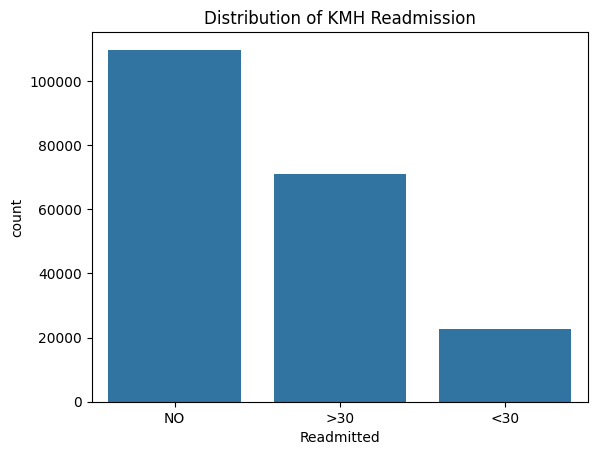

In [71]:
#sns.countplot(x='readmitted', data=df)
#plt.title('Distribution of KMH-Readmission')
#plt.show()
sns.countplot(data=df, x='Readmitted')
plt.title('Distribution of KMH Readmission')
plt.show()

### Checking for unique values in categorical columns

In [72]:
print(df['Race'].value_counts())
print(df['Gender'].value_counts())
print(df['A1Cresult'].value_counts())
print(df['max_glu_serum'].value_counts())

Race
Shona                 152176
Ndebele                38420
?                       4546
Whites/Coloureds        4074
Other_EthnicGroups      3012
Tonga                   1282
Shona                     22
Name: count, dtype: int64
Gender
Female             109416
Male                94110
Unknown/Invalid         6
Name: count, dtype: int64
A1Cresult
>8      16432
Norm     9980
>7       7624
Name: count, dtype: int64
max_glu_serum
Norm    5194
>200    2970
>300    2528
Name: count, dtype: int64



#### Map column names to our expected features

In [73]:
column_mapping = {
    'time_in_hospital': 'time_in_hospital',
    'Speciality': 'medical_specialty',
    'Lab Procedures': 'n_lab_procedures',
    '# Of Procedures': 'n_procedures',
    '# of Medication': 'n_medications',
    'Outpatient #': 'n_outpatient',
    'Inpatient #': 'n_inpatient',
    'Diagnosis 1': 'diag_1',
    'Diagnosis 2': 'diag_2',
    'Diagnosis 3': 'diag_3',
    'max_glu_serum': 'glucose_test',
    'A1Cresult': 'A1Ctest',
    'DiabetesMed': 'diabetes_med',
    'Readmitted': 'readmitted'
}

In [74]:
df = df.rename(columns=column_mapping)  # Rename columns

#### Prepare target variable (convert to binary)

In [75]:
df['readmitted'] = df['readmitted'].apply(lambda x: 1 if str(x).lower() in ['yes', '1', 'true', '<30'] else 0)

### Define features and target

In [76]:
X = df.drop(['readmitted', 'Encounter ID', 'EHR#'], axis=1)  # Remove ID columns
y = df['readmitted']

 ### Split Dataset.
Datasets are split into training and testing subsets

In [77]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [78]:

numeric_features = ['time_in_hospital', 'n_lab_procedures', 'n_procedures',      # Categorizing features into categorical and numeric
                   'n_medications', 'n_outpatient', 'n_inpatient']
categorical_features = ['Race', 'Gender', 'Age', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3',
                       'glucose_test', 'A1Ctest', 'change', 'diabetes_med']

In [79]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Define your feature columns
numeric_features = ['time_in_hospital', 'n_medications']  # numerical columns
categorical_features = ['Gender', 'diabetes_med']  # categorical columns

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(), categorical_features)
    ]
)

In [80]:
# Build and train model
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=150,
        max_depth=7,
        random_state=42,
        class_weight='balanced'
    ))
])

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

In [81]:
print("Columns in X_train:", X_train.columns.tolist())

Columns in X_train: ['Race', 'Gender', 'Age', 'time_in_hospital', 'medical_specialty', 'n_lab_procedures', 'n_procedures', 'n_medications', 'n_outpatient', 'n_inpatient', 'diag_1', 'diag_2', 'diag_3', ' # of diagnoses', 'glucose_test', 'A1Ctest', 'Metformin', 'Repaglinide', 'Nateglinide', 'Chlorpropamide', 'Glimepiride', 'Acetohexamide', 'Glipizide', 'Glyburide', 'Tolbutamide', 'Pioglitazone', 'Rosiglitazone', 'Acarbose', 'Miglitol', 'Troglitazone', 'Tolazamide', 'Examide', 'Citoglipton', 'Insulin', 'Glyburide-metformin', 'glipizide-metformin', 'Glimepiride-pioglitazone', 'metformin-rosiglitazone', 'Metformin-pioglitazone', 'change', 'diabetes_med']


In [82]:
print(X_train.head())
print(X_train.dtypes)  # To check the data types of each column

         Race  Gender      Age  time_in_hospital           medical_specialty  \
19351   Shona  Female  [50-60)                 4  Orthopedics-Reconstructive   
100007  Shona    Male  [60-70)                 3                           ?   
120032  Shona    Male  [60-70)                 4                           ?   
159170  Shona  Female  [80-90)                 5                           ?   
170819  Shona  Female  [80-90)                 7             Surgery-General   

        n_lab_procedures  n_procedures  n_medications  n_outpatient  \
19351                 22             1             23             0   
100007                61             0             25             0   
120032                54             0              9             0   
159170                52             0             25             3   
170819                45             0             14             0   

        n_inpatient  ... Examide Citoglipton Insulin  Glyburide-metformin  \
19351          

In [83]:
print(X_train.columns.tolist())

['Race', 'Gender', 'Age', 'time_in_hospital', 'medical_specialty', 'n_lab_procedures', 'n_procedures', 'n_medications', 'n_outpatient', 'n_inpatient', 'diag_1', 'diag_2', 'diag_3', ' # of diagnoses', 'glucose_test', 'A1Ctest', 'Metformin', 'Repaglinide', 'Nateglinide', 'Chlorpropamide', 'Glimepiride', 'Acetohexamide', 'Glipizide', 'Glyburide', 'Tolbutamide', 'Pioglitazone', 'Rosiglitazone', 'Acarbose', 'Miglitol', 'Troglitazone', 'Tolazamide', 'Examide', 'Citoglipton', 'Insulin', 'Glyburide-metformin', 'glipizide-metformin', 'Glimepiride-pioglitazone', 'metformin-rosiglitazone', 'Metformin-pioglitazone', 'change', 'diabetes_med']


#### Evaluate model

In [84]:
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print("Classification Report:")
print(classification_report(y_test, y_pred))
print(f"\nROC AUC Score: {roc_auc_score(y_test, y_proba):.2f}")

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.49      0.64     36117
           1       0.13      0.61      0.22      4590

    accuracy                           0.51     40707
   macro avg       0.52      0.55      0.43     40707
weighted avg       0.82      0.51      0.59     40707


ROC AUC Score: 0.57


 #### Confusion matrix
 Confusion matrix,a visualization technic which is a performance measurement for my machine learning classification model.

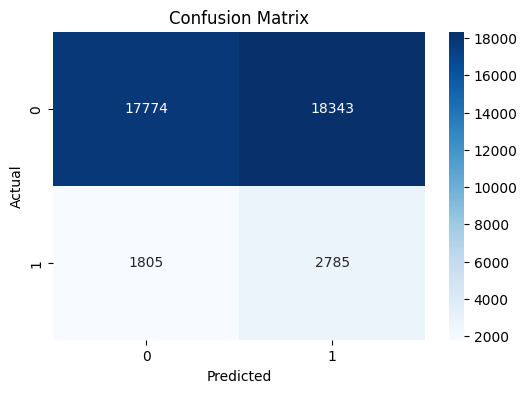

In [85]:
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [86]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Fit the model and assign it to best_model
best_model = model 
best_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

In [87]:
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier())
])
pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

In [88]:
# Save model
import joblib
joblib.dump(model, 'readmission_model.pkl')
print("Model saved as 'readmission_model.pkl'")






Model saved as 'readmission_model.pkl'
